In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import os
from pathlib import Path
import plotly.express as px
import numpy as np

pd.options.mode.chained_assignment = None


In [ ]:
OUTPUT_DIR = Path(r"C:\Users\eduque\Documents\models\sectoral-energy-demands\industry\output_data")

dfs = []
for csv_file in sorted(OUTPUT_DIR.glob("industry_*.csv")):
    df_tmp = pd.read_csv(csv_file, dtype={"country": str, "scenario": str, "carrier": str})
    dfs.append(df_tmp)

df = pd.concat(dfs, ignore_index=True)

# Rename carriers to match plotting convention
df["carrier"] = df["carrier"].replace("oil", "liq. hydrocarbons")
# Drop carriers not used in final energy plotting
df = df[~df["carrier"].isin(["heat", "process emissions", "low-temperature heat"])]

# Fill NaN only in numeric columns to avoid converting string columns to mixed type
numeric_cols = df.select_dtypes(include="number").columns
df[numeric_cols] = df[numeric_cols].fillna(0)

print(f"Loaded {len(dfs)} files  |  {len(df):,} rows")
print(f"Countries : {sorted(df['country'].unique())}")
print(f"Scenarios : {sorted(df['scenario'].unique())}")
print(f"Years     : {sorted(df['year'].unique())}")
print(f"Carriers  : {sorted(df['carrier'].unique())}")


Loaded 16 files  |  576 rows


TypeError: '<' not supported between instances of 'float' and 'str'

In [ ]:
df

,country,scenario,carrier,chemical and petrochemical,construction,food and tobacco,iron and steel,machinery,mining and quarrying,non-ferrous metals,non-metallic minerals,other,paper pulp and print,textile and leather,transport equipment,wood and wood products
0,CL,RF_2030,liq. hydrocarbons,0.000000e+00,847120.41,3.939913e+05,1.643806e+04,18236.33,2.573096e+07,8.732619e+05,6.212030e+06,381820.40,2.530193e+06,729659.93,78822.94,6321.23
1,CL,RF_2030,gas,1.127305e+06,0.00,2.493616e+05,5.373315e+04,0.00,1.842312e+06,0.000000e+00,1.894697e+05,0.00,6.405552e+05,0.00,66276.73,0.00
2,CL,RF_2030,electricity,7.286271e+04,368643.83,1.246808e+06,1.695112e+05,914127.28,3.377572e+07,1.626419e+06,1.709346e+06,333424.57,1.120972e+07,1159060.55,286118.37,47720.08
3,CL,RF_2030,coal,0.000000e+00,0.00,2.992339e+06,2.657459e+05,0.00,0.000000e+00,0.000000e+00,0.000000e+00,0.00,0.000000e+00,0.00,0.00,0.00
4,CL,RF_2030,biomass,0.000000e+00,9539.32,9.974464e+04,6.454146e+04,0.00,0.000000e+00,0.000000e+00,4.273364e+05,0.00,1.761527e+07,17509.34,0.00,3991.68
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,ZA,EL_2050,biomass,0.000000e+00,12848.09,8.084722e+05,3.343281e+06,0.00,0.000000e+00,0.000000e+00,1.924488e+06,0.00,2.886728e+06,31623.81,0.00,7209.41
140,ZA,EL_2050,hydrogen,9.572111e+06,0.00,2.021180e+06,4.715287e+06,0.00,1.441485e+06,7.368281e+05,1.112749e+07,0.00,1.018150e+06,0.00,0.00,0.00
141,ZA,EL_2050,ammonia,5.775828e+05,0.00,0.000000e+00,0.000000e+00,0.00,0.000000e+00,0.000000e+00,0.000000e+00,0.00,0.000000e+00,0.00,0.00,0.00
142,ZA,EL_2050,steel,0.000000e+00,0.00,0.000000e+00,3.674846e+06,0.00,0.000000e+00,0.000000e+00,0.000000e+00,0.00,0.000000e+00,0.00,0.00,0.00


In [ ]:
# =============================================================
# FILTERS — set to None to include all, or provide a list
# =============================================================
SELECTED_COUNTRIES = None          # e.g. ["MA", "EG"] or None for all
SELECTED_SCENARIOS = ["BAU", "Progressive", "Optimistic"]  # exclude Historic baseline
SELECTED_YEARS     = [2030, 2050]  # e.g. [2030, 2050] or None for all years


In [ ]:
# Apply filters
df_filtered = df.copy()
if SELECTED_COUNTRIES:
    df_filtered = df_filtered[df_filtered["country"].isin(SELECTED_COUNTRIES)]
if SELECTED_SCENARIOS:
    df_filtered = df_filtered[df_filtered["scenario"].isin(SELECTED_SCENARIOS)]
if SELECTED_YEARS:
    df_filtered = df_filtered[df_filtered["year"].isin(SELECTED_YEARS)]

# Melt to long format — include year in id_vars
df_long = df_filtered.melt(
    id_vars=["country", "scenario", "year", "carrier"],
    var_name="industry",
    value_name="value"
)

# Industries to aggregate into "all_others"
agg_col = [
    "construction",
    "food and tobacco",
    "machinery",
    "textile and leather",
    "transport equipment",
    "wood and wood products",
]

# Aggregate minor industries
all_others_df = df_long[df_long["industry"].isin(agg_col)].groupby(
    ["country", "scenario", "year", "carrier"]
)["value"].sum().reset_index()
all_others_df["industry"] = "all_others"

# Build aggregated long dataframe
df_long_agg = pd.concat([
    df_long[~df_long["industry"].isin(agg_col)],
    all_others_df
], ignore_index=True)

df_long_agg["value"] = df_long_agg["value"] / 1_000_000  # MWh → TWh

# Convenience: combined scenario_year label for x-axes
df_long_agg["scenario_year"] = df_long_agg["scenario"] + "_" + df_long_agg["year"].astype(str)

print(f"df_long_agg: {len(df_long_agg):,} rows")
print(f"Industries  : {sorted(df_long_agg['industry'].unique())}")
print(f"scenario_year labels: {sorted(df_long_agg['scenario_year'].unique())}")


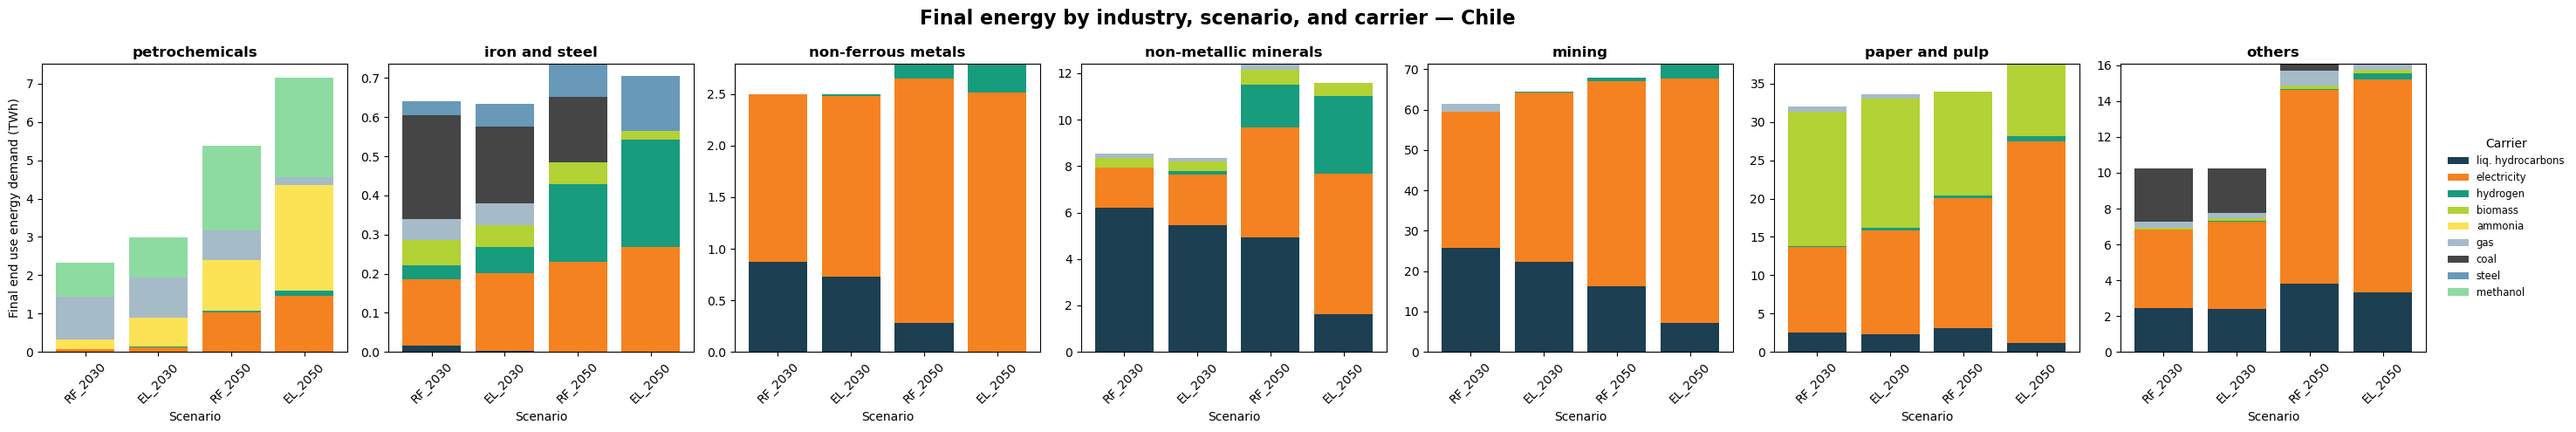

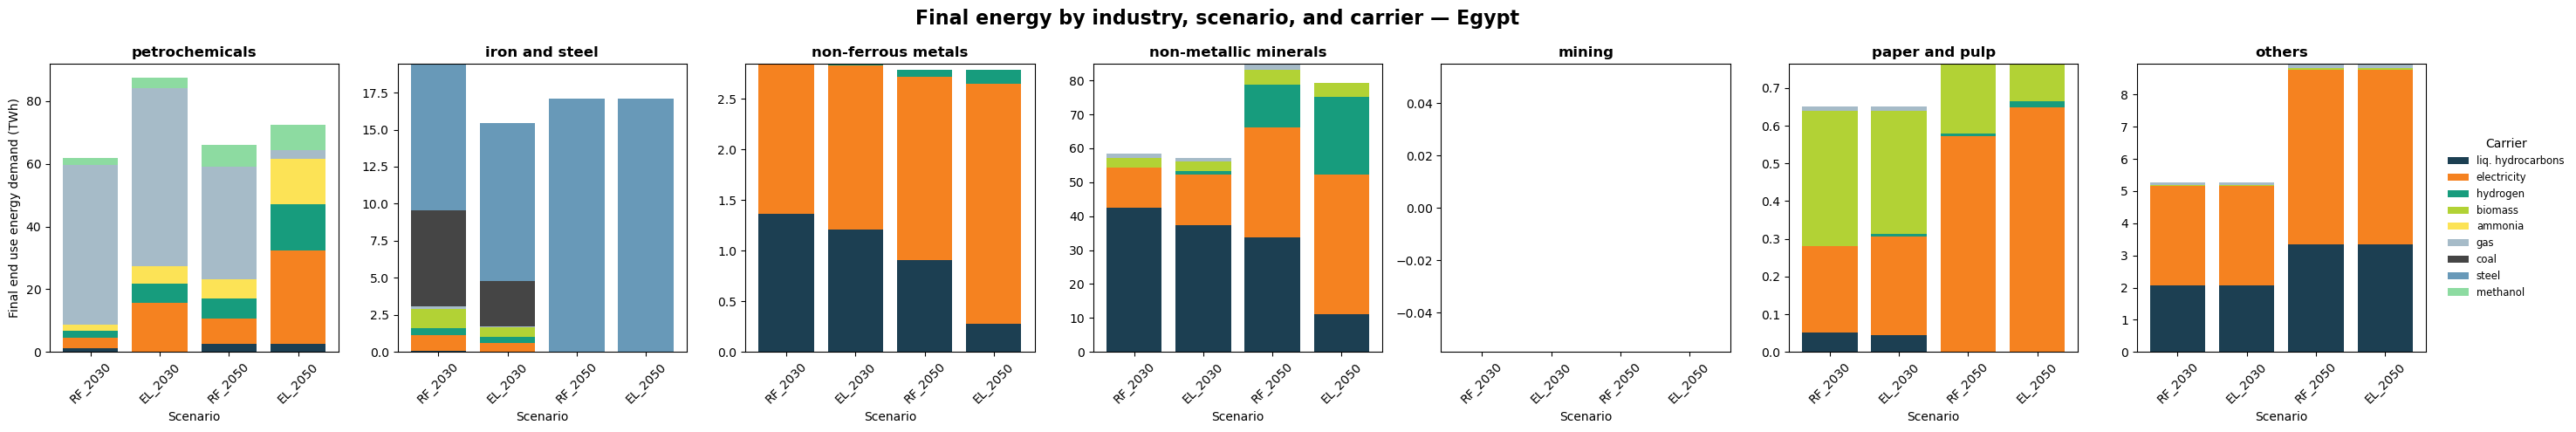

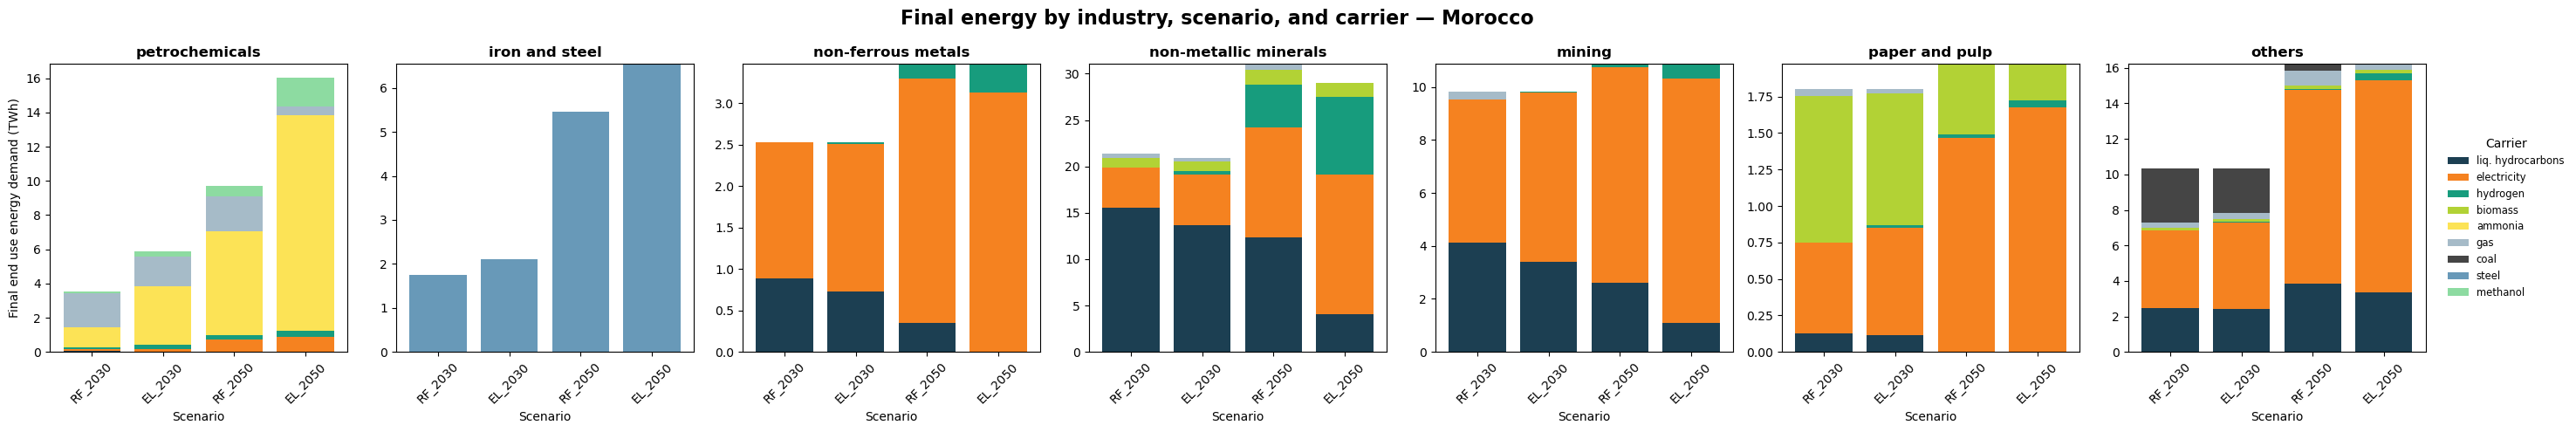

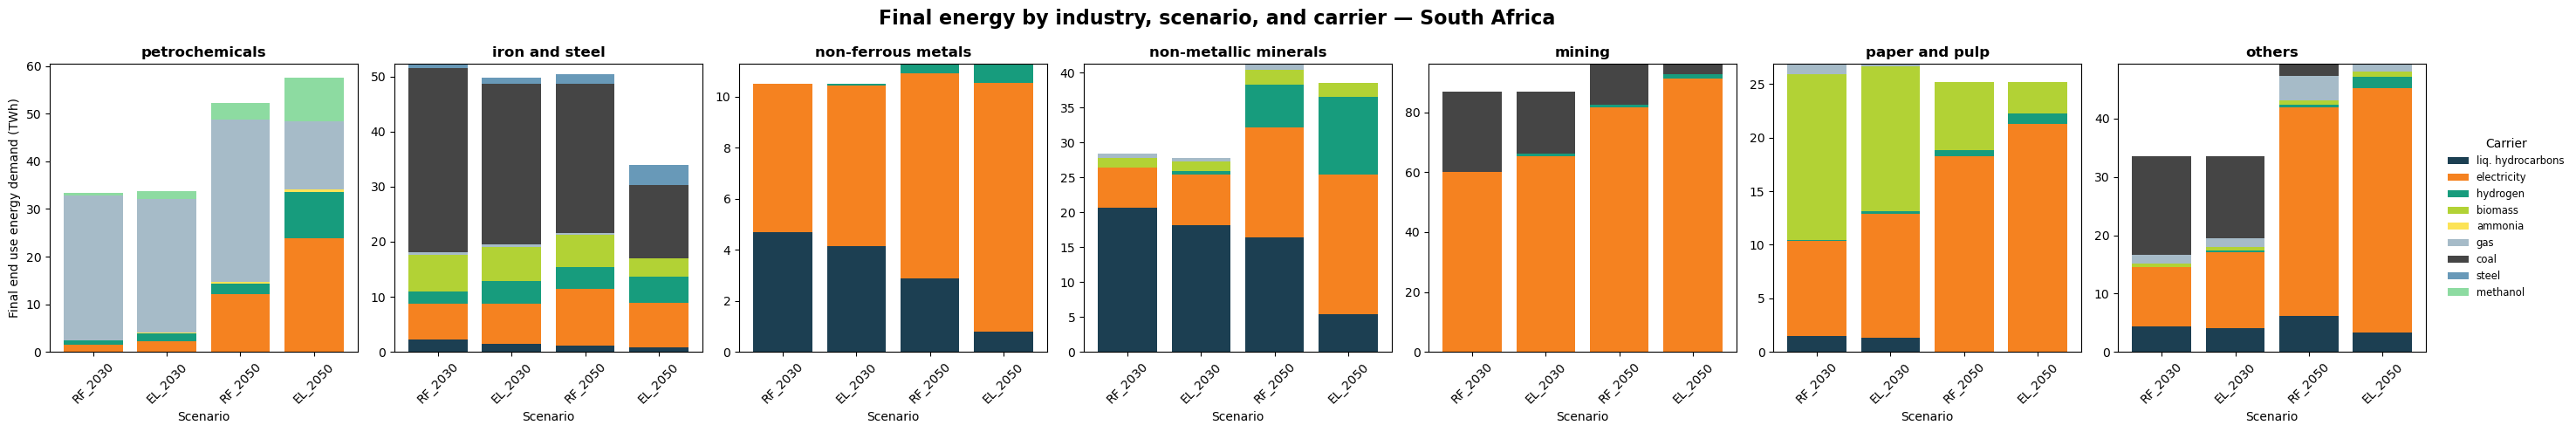

In [ ]:
industry_colors = {
    'chemical and petrochemical': '#1c3f52',
    'iron and steel': '#b2d235',
    'non-ferrous metals': '#a6bbc8',
    'non-metallic minerals': '#008598',
    'mining and quarrying': '#e377c2',
    'paper pulp and print': '#228b22',
    'all_others': '#FCD80E',
}
industry_carrier_colors = {
    'liq. hydrocarbons': '#1c3f52',
    'electricity': '#f58220',
    'hydrogen': '#179c7d',
    'biomass': '#b2d235',
    'ammonia': '#fce356',
    'gas': '#a6bbc8',
    'coal': '#454545',
    'methanol': '#8ddba1',
}
facet_name_map = {
    'chemical and petrochemical': 'petrochemicals',
    'iron and steel': 'iron and steel',
    'mining and quarrying': 'mining',
    'non-ferrous metals': 'non-ferrous metals',
    'non-metallic minerals': 'non-metallic minerals',
    'all_others': 'others',
    'paper pulp and print': 'paper and pulp',
}
country_dic = {"MA": "Morocco", "EG": "Egypt", "ZA": "South Africa", "NA": "Namibia"}
industry_order = list(industry_colors.keys())
carrier_order  = list(industry_carrier_colors.keys())

# Build ordered scenario_year axis labels from the actual data
_scenario_base = ["Historic", "BAU", "Progressive", "Optimistic"]
scenario_year_order = [
    f"{sc}_{yr}"
    for sc in _scenario_base
    for yr in sorted(df_long_agg["year"].unique())
    if f"{sc}_{yr}" in df_long_agg["scenario_year"].values
]

for cty, d in df_long_agg.groupby("country"):
    full_name = country_dic.get(cty, cty)
    n_industries = len(industry_order)
    fig, axs = plt.subplots(1, n_industries, figsize=(4 * n_industries, 5), sharey=False)
    for i, industry in enumerate(industry_order):
        ax = axs[i]
        d_ind = d[d["industry"] == industry].copy()
        d_ind["scenario_year"] = pd.Categorical(
            d_ind["scenario_year"], categories=scenario_year_order, ordered=True
        )
        pivot = d_ind.pivot_table(
            index="scenario_year", columns="carrier", values="value",
            aggfunc="sum", observed=False
        ).fillna(0)
        for carrier in carrier_order:
            if carrier not in pivot.columns:
                pivot[carrier] = 0
        pivot = pivot[carrier_order]
        bottom = np.zeros(len(pivot))
        for carrier in carrier_order:
            values = pivot[carrier].values
            ax.bar(pivot.index, values, bottom=bottom,
                   color=industry_carrier_colors[carrier], label=carrier)
            bottom += values
        ax.set_title(facet_name_map.get(industry, industry), fontsize=11, weight='bold')
        ax.set_xlabel('')
        if i == 0:
            ax.set_ylabel('Final energy demand (TWh)')
        ax.tick_params(axis='x', rotation=60, labelsize=8)
    fig.suptitle(
        f"Final energy by industry, scenario & year — {full_name}",
        fontsize=14, weight='bold'
    )
    fig.legend(carrier_order, title="Carrier", loc='center left',
               bbox_to_anchor=(1.0, 0.5), fontsize='small', frameon=False)
    plt.tight_layout()
    plt.show()


In [ ]:
# NOTE: Egypt does not have mining as demand because there was no data available on that regard in any reliable source.

In [ ]:
from IPython.display import display

# Pivot table: country × industry × scenario_year → carriers as columns
industry_type_table = df_long_agg.pivot_table(
    index=["country", "industry", "scenario_year"],
    columns="carrier",
    values="value",
    aggfunc="sum"
).reindex(columns=carrier_order).reset_index()

industry_type_table["country"] = industry_type_table["country"].map(
    lambda c: country_dic.get(c, c)
)

display(industry_type_table)


carrier,country,industry,scenario,liq. hydrocarbons,electricity,hydrogen,biomass,ammonia,gas,coal,steel,methanol
0,Chile,all_others,EL_2030,2.411087,4.854626,0.049872,0.130785,0.000000,0.315638,2.493616,0.0,0.000000
1,Chile,all_others,EL_2050,3.335122,11.853978,0.355995,0.194079,0.000000,0.333300,0.000000,0.0,0.000000
2,Chile,all_others,RF_2030,2.455973,4.355903,0.004987,0.130785,0.000000,0.315638,2.992339,0.0,0.000000
3,Chile,all_others,RF_2050,3.833515,10.785993,0.071199,0.194079,0.000000,0.831693,0.355995,0.0,0.000000
4,Chile,chemical and petrochemical,EL_2030,0.000000,0.119574,0.011400,0.000000,0.755668,1.060244,0.000000,0.0,1.044839
...,...,...,...,...,...,...,...,...,...,...,...,...
107,South Africa,non-metallic minerals,RF_2050,16.389904,15.728200,6.184389,2.061463,0.000000,0.865305,0.000000,0.0,0.000000
108,South Africa,paper pulp and print,EL_2030,1.348962,11.567817,0.227795,13.518296,0.000000,0.209987,0.000000,0.0,0.000000
109,South Africa,paper pulp and print,EL_2050,0.000000,21.269885,1.018150,2.886728,0.000000,0.000000,0.000000,0.0,0.000000
110,South Africa,paper pulp and print,RF_2030,1.523686,8.873362,0.024417,15.533252,0.000000,0.918141,0.000000,0.0,0.000000


In [ ]:
# TODO WHY THERE IS NO AMMONIA!!!!???

In [ ]:
# Colour and order configuration — shared by the aggregate charts below
industry_carrier_colors = {
    'liq. hydrocarbons': '#1c3f52',
    'electricity': '#f58220',
    'hydrogen': '#179c7d',
    'biomass': '#b2d235',
    'ammonia': '#fce356',
    'gas': '#a6bbc8',
    'coal': '#454545',
    'methanol': '#8ddba1',
}
carrier_order       = list(industry_carrier_colors.keys())
scenario_year_order = [
    f"{sc}_{yr}"
    for sc in ["Historic", "BAU", "Progressive", "Optimistic"]
    for yr in sorted(df_long_agg["year"].unique())
    if f"{sc}_{yr}" in df_long_agg["scenario_year"].values
]
country_dic = {"MA": "Morocco", "EG": "Egypt", "ZA": "South Africa", "NA": "Namibia"}


In [ ]:
df_long_agg.carrier.unique()

array(['liq. hydrocarbons', 'gas', 'electricity', 'coal', 'biomass',
       'hydrogen', 'ammonia', 'steel', 'methanol'], dtype=object)

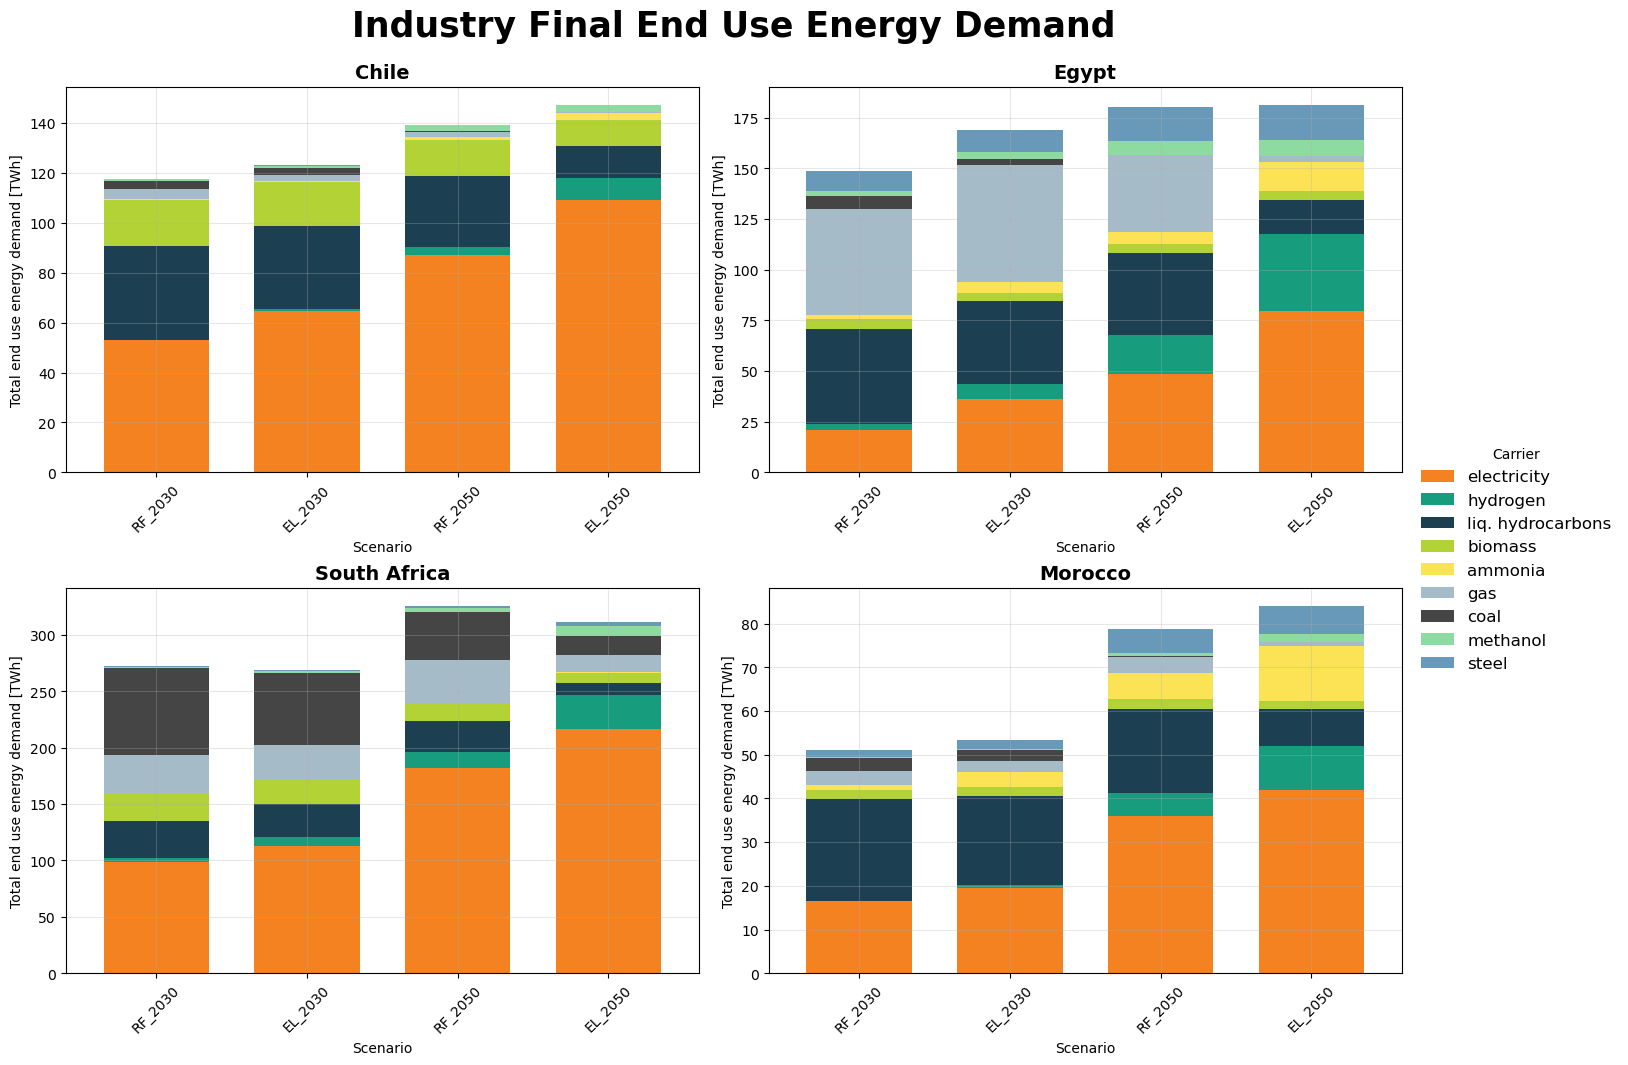

In [ ]:
def plot_industry_bar_agg(df_agg, country_code, ax, country_dic=country_dic):
    """Stacked bar chart: total industry energy by scenario_year, coloured by carrier."""
    df_country = (
        df_agg[df_agg["country"] == country_code]
        .groupby(["scenario_year", "carrier"], as_index=False)["value"]
        .sum()
    )
    df_country["scenario_year"] = pd.Categorical(
        df_country["scenario_year"], categories=scenario_year_order, ordered=True
    )
    df_pivot = (
        df_country.pivot(index="scenario_year", columns="carrier", values="value")
        .fillna(0)
        .reindex(columns=carrier_order, fill_value=0)
    )
    colors = [industry_carrier_colors.get(c, "#cccccc") for c in df_pivot.columns]
    df_pivot.plot.bar(ax=ax, color=colors, width=0.7, legend=False, stacked=True)
    ax.set_title(country_dic.get(country_code, country_code), fontsize=14, weight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Total final energy demand [TWh]")
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=45)

countries = sorted(df_long_agg["country"].unique())
ncols = min(2, len(countries))
nrows = int(np.ceil(len(countries) / ncols))

fig, axs = plt.subplots(nrows, ncols, figsize=(7 * ncols, 5 * nrows), constrained_layout=True)
axs_flat = np.array(axs).flatten()

for idx, cty in enumerate(countries):
    plot_industry_bar_agg(df_long_agg, cty, axs_flat[idx])

# Hide unused axes
for ax in axs_flat[len(countries):]:
    ax.set_visible(False)

fig.suptitle("Industry Final End-Use Energy Demand", fontsize=20, weight="bold")
handles, labels = axs_flat[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Carrier", loc="center left",
           bbox_to_anchor=(1.0, 0.5), fontsize="large", frameon=False)
plt.show()


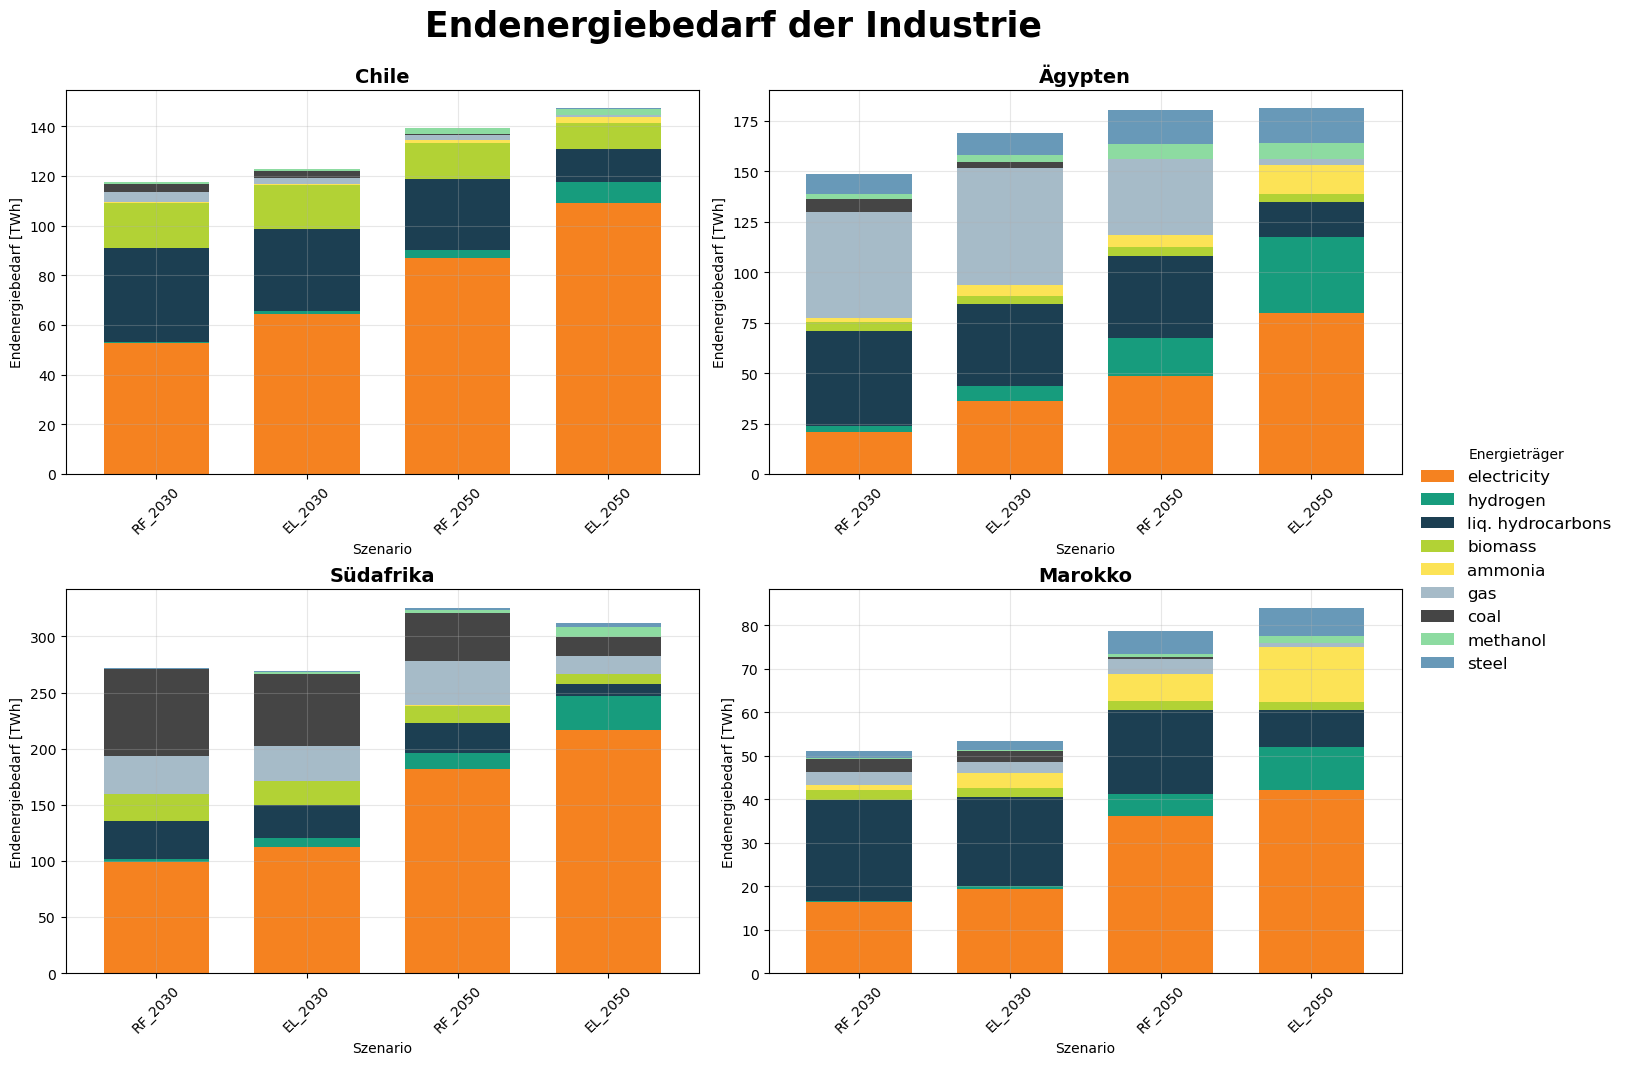

In [ ]:
country_dic_de = {"MA": "Marokko", "EG": "Ägypten", "ZA": "Südafrika", "NA": "Namibia"}

def plot_industry_bar_agg_de(df_agg, country_code, ax):
    """German-labelled stacked bar chart: total industry energy by scenario_year."""
    df_country = (
        df_agg[df_agg["country"] == country_code]
        .groupby(["scenario_year", "carrier"], as_index=False)["value"]
        .sum()
    )
    df_country["scenario_year"] = pd.Categorical(
        df_country["scenario_year"], categories=scenario_year_order, ordered=True
    )
    df_pivot = (
        df_country.pivot(index="scenario_year", columns="carrier", values="value")
        .fillna(0)
        .reindex(columns=carrier_order, fill_value=0)
    )
    colors = [industry_carrier_colors.get(c, "#cccccc") for c in df_pivot.columns]
    df_pivot.plot.bar(ax=ax, color=colors, width=0.7, legend=False, stacked=True)
    ax.set_title(country_dic_de.get(country_code, country_code), fontsize=14, weight="bold")
    ax.set_xlabel("Szenario / Jahr")
    ax.set_ylabel("Endenergiebedarf [TWh]")
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=45)

countries = sorted(df_long_agg["country"].unique())
ncols = min(2, len(countries))
nrows = int(np.ceil(len(countries) / ncols))

fig, axs = plt.subplots(nrows, ncols, figsize=(7 * ncols, 5 * nrows), constrained_layout=True)
axs_flat = np.array(axs).flatten()

for idx, cty in enumerate(countries):
    plot_industry_bar_agg_de(df_long_agg, cty, axs_flat[idx])

for ax in axs_flat[len(countries):]:
    ax.set_visible(False)

fig.suptitle("Endenergiebedarf der Industrie", fontsize=20, weight="bold")
handles, labels = axs_flat[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Energieträger", loc="center left",
           bbox_to_anchor=(1.0, 0.5), fontsize="large", frameon=False)
plt.show()


In [ ]:
# ── ADDITIONAL FILTERED ANALYSIS ──────────────────────────────────────────────
# Set country, scenario(s), and years for the charts below.
# These are independent from the global SELECTED_* filters above.
FOCUS_COUNTRY   = "MA"                                    # single ISO-2 code
FOCUS_SCENARIOS = ["BAU", "Progressive", "Optimistic"]   # subset or all
FOCUS_YEARS     = None                                    # None = all available years


In [ ]:
# Chart A — selected country: total energy evolution over years, one subplot per scenario
# X = year, stacked bars by carrier

# Use the full (unfiltered) df_long before global SELECTED_* reduce its scope
df_focus = df.copy()
df_focus["carrier"] = df_focus["carrier"].replace("oil", "liq. hydrocarbons")
df_focus = df_focus[~df_focus["carrier"].isin(["heat", "process emissions"])]
df_focus = df_focus.fillna(0)

df_focus = df_focus[df_focus["country"] == FOCUS_COUNTRY]
if FOCUS_SCENARIOS:
    df_focus = df_focus[df_focus["scenario"].isin(FOCUS_SCENARIOS)]
if FOCUS_YEARS:
    df_focus = df_focus[df_focus["year"].isin(FOCUS_YEARS)]

# Melt and compute total per year × carrier × scenario
df_focus_long = df_focus.melt(
    id_vars=["country", "scenario", "year", "carrier"],
    var_name="industry", value_name="value"
)
df_focus_total = (
    df_focus_long.groupby(["scenario", "year", "carrier"], as_index=False)["value"]
    .sum()
)
df_focus_total["value"] /= 1_000_000  # MWh → TWh

scenarios_present = [s for s in ["Historic", "BAU", "Progressive", "Optimistic"]
                     if s in df_focus_total["scenario"].unique()]

fig, axs = plt.subplots(1, len(scenarios_present),
                        figsize=(5 * len(scenarios_present), 5),
                        sharey=True, constrained_layout=True)
if len(scenarios_present) == 1:
    axs = [axs]

for ax, sc in zip(axs, scenarios_present):
    d_sc = df_focus_total[df_focus_total["scenario"] == sc]
    pivot = (
        d_sc.pivot(index="year", columns="carrier", values="value")
        .fillna(0)
        .reindex(columns=carrier_order, fill_value=0)
    )
    colors = [industry_carrier_colors.get(c, "#cccccc") for c in pivot.columns]
    pivot.plot.bar(ax=ax, color=colors, width=0.7, stacked=True, legend=False)
    ax.set_title(sc, fontsize=12, weight="bold")
    ax.set_xlabel("Year")
    ax.set_ylabel("Total final energy [TWh]" if sc == scenarios_present[0] else "")
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=0)

full_name = country_dic.get(FOCUS_COUNTRY, FOCUS_COUNTRY)
fig.suptitle(f"{full_name} — Industry energy by carrier & scenario", fontsize=14, weight="bold")
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Carrier", loc="center left",
           bbox_to_anchor=(1.0, 0.5), fontsize="small", frameon=False)
plt.show()


In [ ]:
# Chart B — cross-country comparison for a specific year and scenario
# Uses FOCUS_SCENARIOS[0] and the last year in FOCUS_YEARS (or latest available)

_compare_scenarios = FOCUS_SCENARIOS if FOCUS_SCENARIOS else ["BAU"]
_compare_year = (FOCUS_YEARS[-1] if FOCUS_YEARS
                 else int(df_focus_long["year"].max()) if len(df_focus_long) > 0
                 else 2050)

df_compare = df.copy()
df_compare["carrier"] = df_compare["carrier"].replace("oil", "liq. hydrocarbons")
df_compare = df_compare[~df_compare["carrier"].isin(["heat", "process emissions"])]
df_compare = df_compare.fillna(0)
df_compare = df_compare[
    (df_compare["scenario"].isin(_compare_scenarios)) &
    (df_compare["year"] == _compare_year)
]

df_compare_long = df_compare.melt(
    id_vars=["country", "scenario", "year", "carrier"],
    var_name="industry", value_name="value"
)
df_compare_total = (
    df_compare_long.groupby(["country", "scenario", "carrier"], as_index=False)["value"]
    .sum()
)
df_compare_total["value"] /= 1_000_000  # MWh → TWh
df_compare_total["country_name"] = df_compare_total["country"].map(
    lambda c: country_dic.get(c, c)
)

scenarios_to_plot = [s for s in ["Historic", "BAU", "Progressive", "Optimistic"]
                     if s in df_compare_total["scenario"].unique()]

fig, axs = plt.subplots(1, len(scenarios_to_plot),
                        figsize=(5 * len(scenarios_to_plot), 5),
                        sharey=True, constrained_layout=True)
if len(scenarios_to_plot) == 1:
    axs = [axs]

for ax, sc in zip(axs, scenarios_to_plot):
    d_sc = df_compare_total[df_compare_total["scenario"] == sc]
    pivot = (
        d_sc.pivot(index="country_name", columns="carrier", values="value")
        .fillna(0)
        .reindex(columns=carrier_order, fill_value=0)
    )
    colors = [industry_carrier_colors.get(c, "#cccccc") for c in pivot.columns]
    pivot.plot.bar(ax=ax, color=colors, width=0.6, stacked=True, legend=False)
    ax.set_title(sc, fontsize=12, weight="bold")
    ax.set_xlabel("Country")
    ax.set_ylabel("Total final energy [TWh]" if sc == scenarios_to_plot[0] else "")
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=30)

fig.suptitle(f"Cross-country comparison — {_compare_year}", fontsize=14, weight="bold")
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Carrier", loc="center left",
           bbox_to_anchor=(1.0, 0.5), fontsize="small", frameon=False)
plt.show()
